##  **DATA ANALYSIS PYTHON PROJECT - BLINKIT ANALYSIS**

###  **IMPORT LIBRARIES**

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###  **IMPORT RAW DATA**

In [41]:
df = pd.read_csv("C:/Users/SANKET/Downloads/blinkit_data.csv")

###  **SAMPLE DATA**

In [42]:
df.head(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2000,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


In [43]:
df.tail(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8513,Regular,DRY23,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.108568,NaN,42.9112,4.0
8514,low fat,FDA11,Baking Goods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.043029,NaN,94.7436,4.0
8515,low fat,FDK38,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.053032,NaN,149.1734,4.0
8516,low fat,FDO38,Canned,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.072486,NaN,78.9986,4.0
8517,low fat,FDG32,Fruits and Vegetables,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.175143,NaN,222.3772,4.0
8518,low fat,NCT53,Health and Hygiene,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,1998,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


###  **SIZE OF  DATA**

In [44]:
print("Size of Data = ",df.shape)

Size of Data =  (8523, 12)


###  **FIELD INFO.**

In [45]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

###  **DATA TYPES.**

In [46]:
df.dtypes

Item Fat Content                 str
Item Identifier                  str
Item Type                        str
Outlet Establishment Year      int64
Outlet Identifier                str
Outlet Location Type             str
Outlet Size                      str
Outlet Type                      str
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

###  **DATA CLEANING**

In [47]:
print(df["Item Fat Content"].unique())

<StringArray>
['Regular', 'Low Fat', 'low fat', 'LF', 'reg']
Length: 5, dtype: str


In [48]:
df["Item Fat Content"]=df["Item Fat Content"].replace({"LF":"Low Fat",
                                                       "low fat":"Low Fat",
                                                      "reg":"Regular"})

In [49]:
print(df["Item Fat Content"].unique())

<StringArray>
['Regular', 'Low Fat']
Length: 2, dtype: str


###  **BUSINESS REQUIREMENTS**

###  **KPI's  REQUIREMENTS**

In [50]:
#Total Sales
total_sales=df["Sales"].sum()

#Average Sales
avg_sales=df["Sales"].mean()

#No. of Items Sold
no_of_items_sold=df["Sales"].count()

#Average Ratings
avg_ratings=df["Rating"].mean()

#Display

print(f"Total Sales: ${total_sales:,.0f}")

print(f"Average Sales: ${avg_sales:,.1f}")

print(f"No of Items Sold: {no_of_items_sold:,.0f}")

print(f"Average Ratings:{avg_ratings:,.1f}")

Total Sales: $1,201,681
Average Sales: $141.0
No of Items Sold: 8,523
Average Ratings:4.0


###  **CHARTS  REQUIREMENTS**

### **Total Sales by Fat Content**

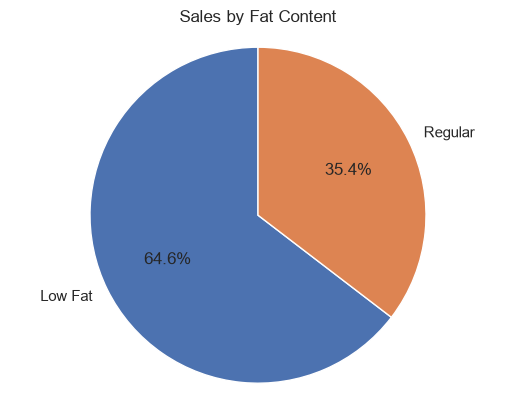

In [51]:
sales_by_fat =df.groupby("Item Fat Content")["Sales"].sum()

plt.pie(sales_by_fat,labels=sales_by_fat.index,
                        autopct = "%.1f%%",
                        startangle = 90)
plt.title("Sales by Fat Content")
plt.axis("equal")
plt.show()

### **Total Sales by Item Type**

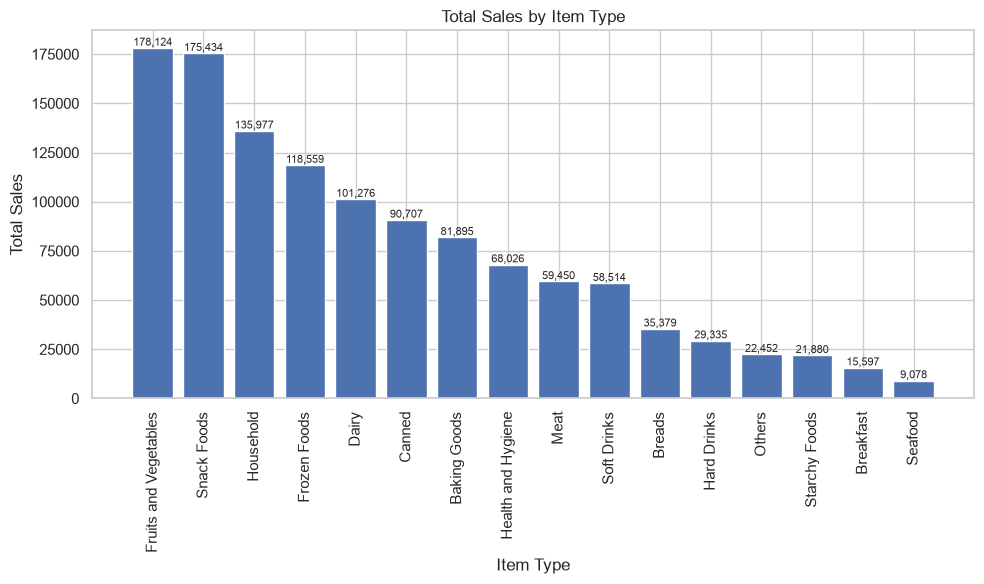

In [52]:
sales_by_type= df.groupby("Item Type")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))
bars=plt.bar(sales_by_type.index, sales_by_type.values)


plt.xticks(rotation=90)
plt.xlabel("Item Type")
plt.ylabel("Total Sales")
plt.title("Total Sales by Item Type")

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2,bar.get_height(),
             f'{bar.get_height():,.0f}', ha='center' , va='bottom',fontsize=8)
    
plt.tight_layout()
plt.show()

### **Fat Content by Outlet for Total Sales**

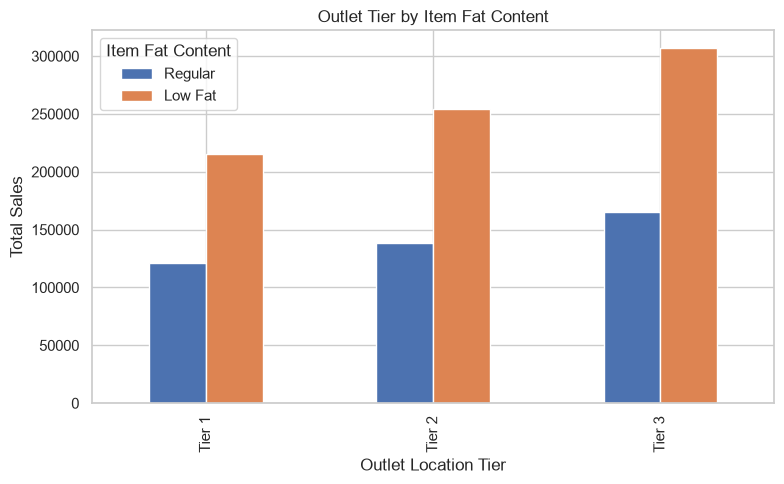

In [53]:
grouped= df.groupby(["Outlet Location Type","Item Fat Content"])["Sales"].sum().unstack()
grouped=grouped[["Regular","Low Fat"]]

ax= grouped.plot(kind="bar", figsize=(8,5),title="Outlet Tier by Item Fat Content")
plt.xlabel("Outlet Location Tier")
plt.ylabel("Total Sales")
plt.legend(title="Item Fat Content")
plt.tight_layout()
plt.show()

### **Total Sales by Outlet Establishment**

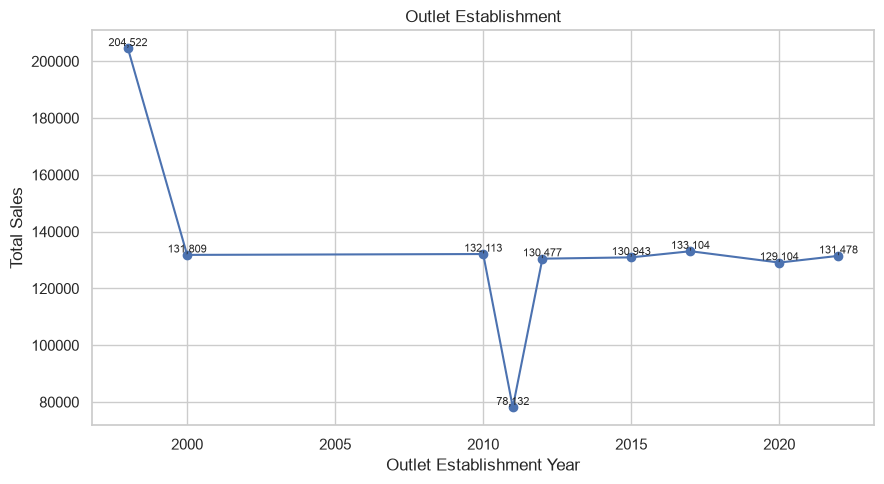

In [54]:
sales_by_year = df.groupby("Outlet Establishment Year")["Sales"].sum().sort_index()

plt.figure(figsize=(9,5))
plt.plot(sales_by_year.index, sales_by_year.values, marker="o", linestyle="-")

plt.xlabel("Outlet Establishment Year")
plt.ylabel("Total Sales")
plt.title("Outlet Establishment")

for x,y in zip(sales_by_year.index, sales_by_year.values):
    plt.text(x,y, f"{y:,.0f}", ha="center", va= "bottom", fontsize=8)
    
plt.tight_layout()
plt.show()

### **Sales by Outlet Size**

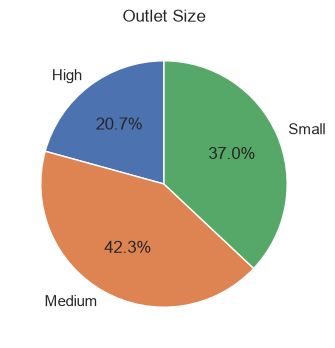

In [55]:
sales_by_size = df.groupby("Outlet Size")["Sales"].sum()

plt.figure(figsize=(4, 4))
plt.pie(sales_by_size, labels=sales_by_size.index, autopct="%1.1f%%", startangle=90)
plt.title("Outlet Size")
plt.tight_layout
plt.show()

### **Sales by Outlet Location**

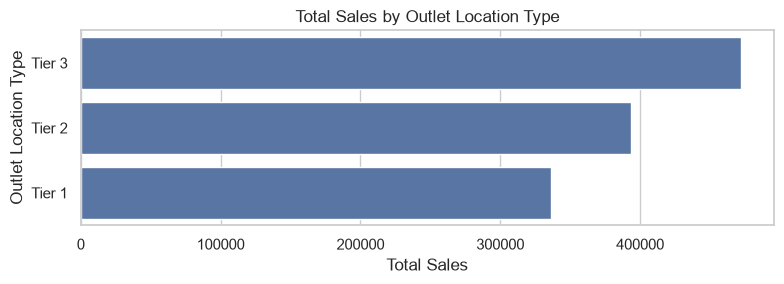

In [56]:
sales_by_location = df.groupby("Outlet Location Type")["Sales"].sum().reset_index()
sales_by_location = sales_by_location.sort_values("Sales", ascending=False)

plt.figure(figsize=(8,3))
ax = sns.barplot(x="Sales", y="Outlet Location Type", data=sales_by_location)

plt.title("Total Sales by Outlet Location Type")
plt.xlabel("Total Sales")
plt.ylabel("Outlet Location Type")

plt.tight_layout()
plt.show()

# **DASHBOARD**

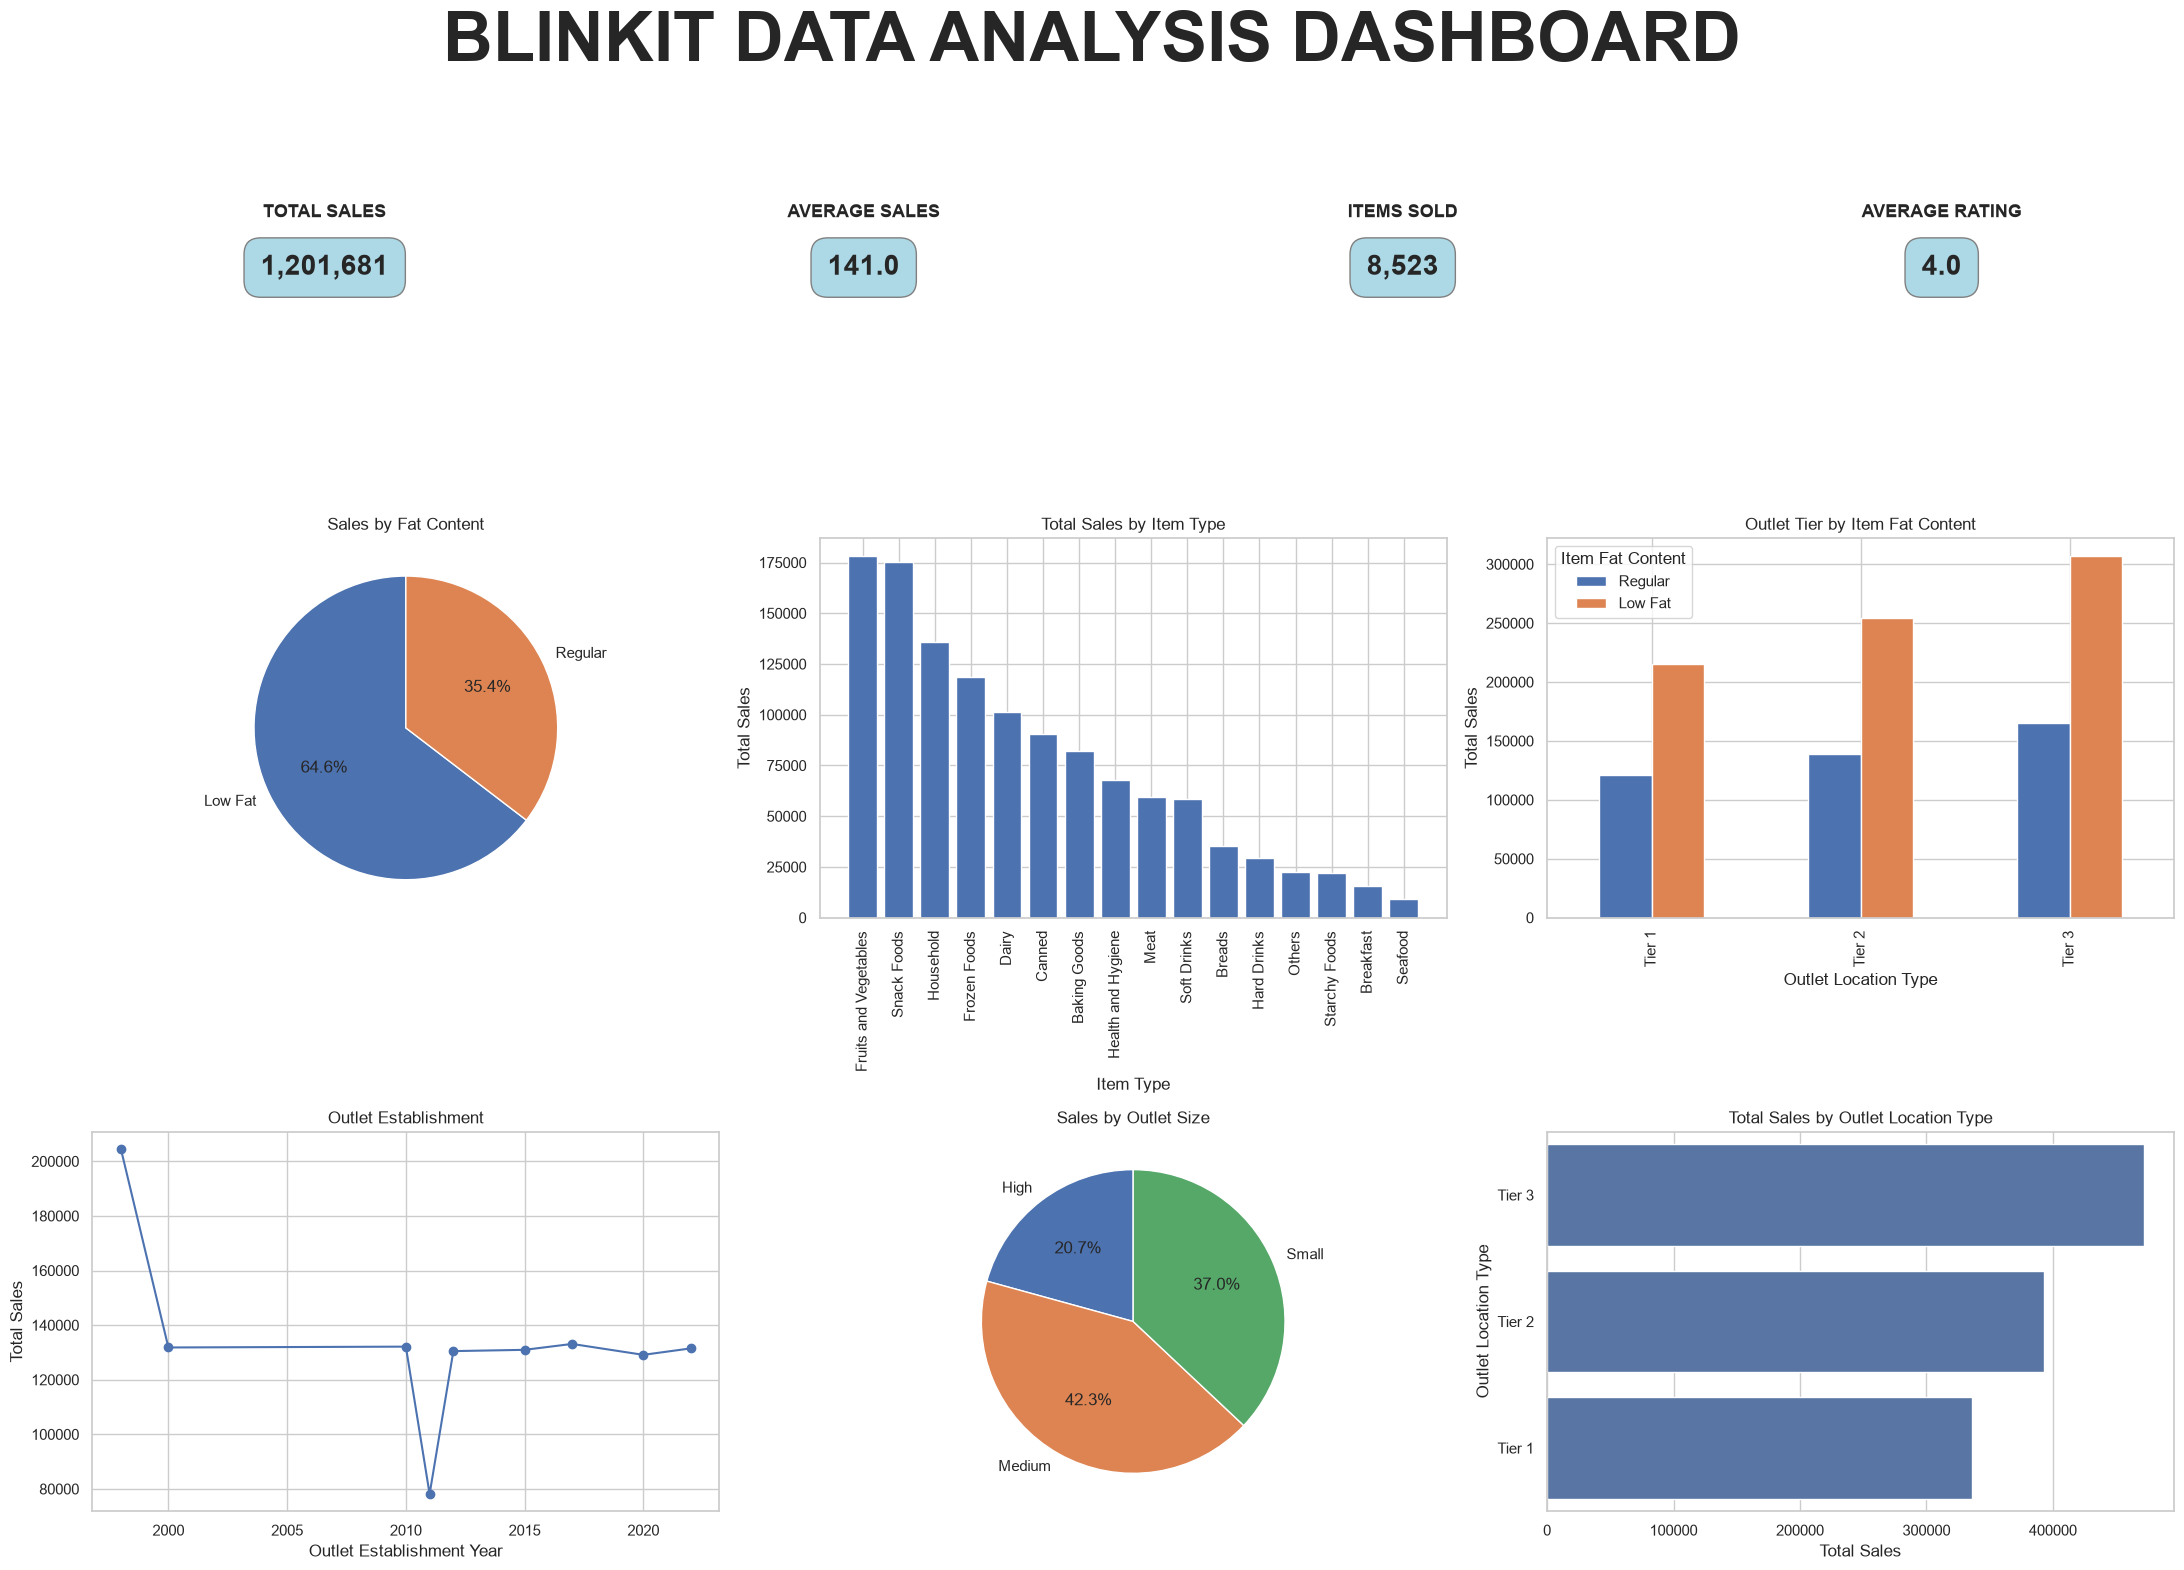

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dashboard background
sns.set_theme(style="whitegrid")

# Create dashboard
fig = plt.figure(figsize=(22, 16))

fig.suptitle(
    "BLINKIT DATA ANALYSIS DASHBOARD",
    fontsize=50,
    fontweight="bold"
)

gs = fig.add_gridspec(
    3, 3,
    height_ratios=[0.65, 1.5, 1.5]
)

# ---------------- KPI SECTION ----------------

kpi_grid = gs[0, :].subgridspec(1, 4)

kpis = [
    ("TOTAL SALES", f"{total_sales:,.0f}"),
    ("AVERAGE SALES", f"{avg_sales:,.1f}"),
    ("ITEMS SOLD", f"{no_of_items_sold:,}"),
    ("AVERAGE RATING", f"{avg_ratings:.1f}")
]

for i, (title, value) in enumerate(kpis):

    ax = fig.add_subplot(kpi_grid[0, i])
    ax.axis("off")

    ax.text(
        0.5, 0.65, title,
        ha="center",
        fontsize=13,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.30, value,
        ha="center",
        fontsize=20,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="lightblue",
            edgecolor="gray"
        )
    )

# ---------------- CHART 1 ----------------

ax1 = fig.add_subplot(gs[1, 0])

ax1.pie(
    sales_by_fat,
    labels=sales_by_fat.index,
    autopct="%1.1f%%",
    startangle=90
)

ax1.set_title("Sales by Fat Content")

# ---------------- CHART 2 ----------------

ax2 = fig.add_subplot(gs[1, 1])

ax2.bar(
    sales_by_type.index,
    sales_by_type.values
)

ax2.set_title("Total Sales by Item Type")
ax2.set_xlabel("Item Type")
ax2.set_ylabel("Total Sales")
ax2.tick_params(axis="x", rotation=90)

# ---------------- CHART 3 ----------------

ax3 = fig.add_subplot(gs[1, 2])

grouped.plot(
    kind="bar",
    ax=ax3
)

ax3.set_title("Outlet Tier by Item Fat Content")
ax3.set_xlabel("Outlet Location Type")
ax3.set_ylabel("Total Sales")
ax3.legend(title="Item Fat Content")

# ---------------- CHART 4 ----------------

ax4 = fig.add_subplot(gs[2, 0])

ax4.plot(
    sales_by_year.index,
    sales_by_year.values,
    marker="o",
    linestyle="-"
)

ax4.set_title("Outlet Establishment")
ax4.set_xlabel("Outlet Establishment Year")
ax4.set_ylabel("Total Sales")

# ---------------- CHART 5 ----------------

ax5 = fig.add_subplot(gs[2, 1])

ax5.pie(
    sales_by_size,
    labels=sales_by_size.index,
    autopct="%1.1f%%",
    startangle=90
)

ax5.set_title("Sales by Outlet Size")

# ---------------- CHART 6 ----------------

ax6 = fig.add_subplot(gs[2, 2])

sns.barplot(
    x="Sales",
    y="Outlet Location Type",
    data=sales_by_location,
    ax=ax6
)

ax6.set_title("Total Sales by Outlet Location Type")
ax6.set_xlabel("Total Sales")
ax6.set_ylabel("Outlet Location Type")

# ---------------- FINAL DISPLAY ----------------

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save dashboard
plt.savefig(
    "Blinkit_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **DASHBOARD  Layout**

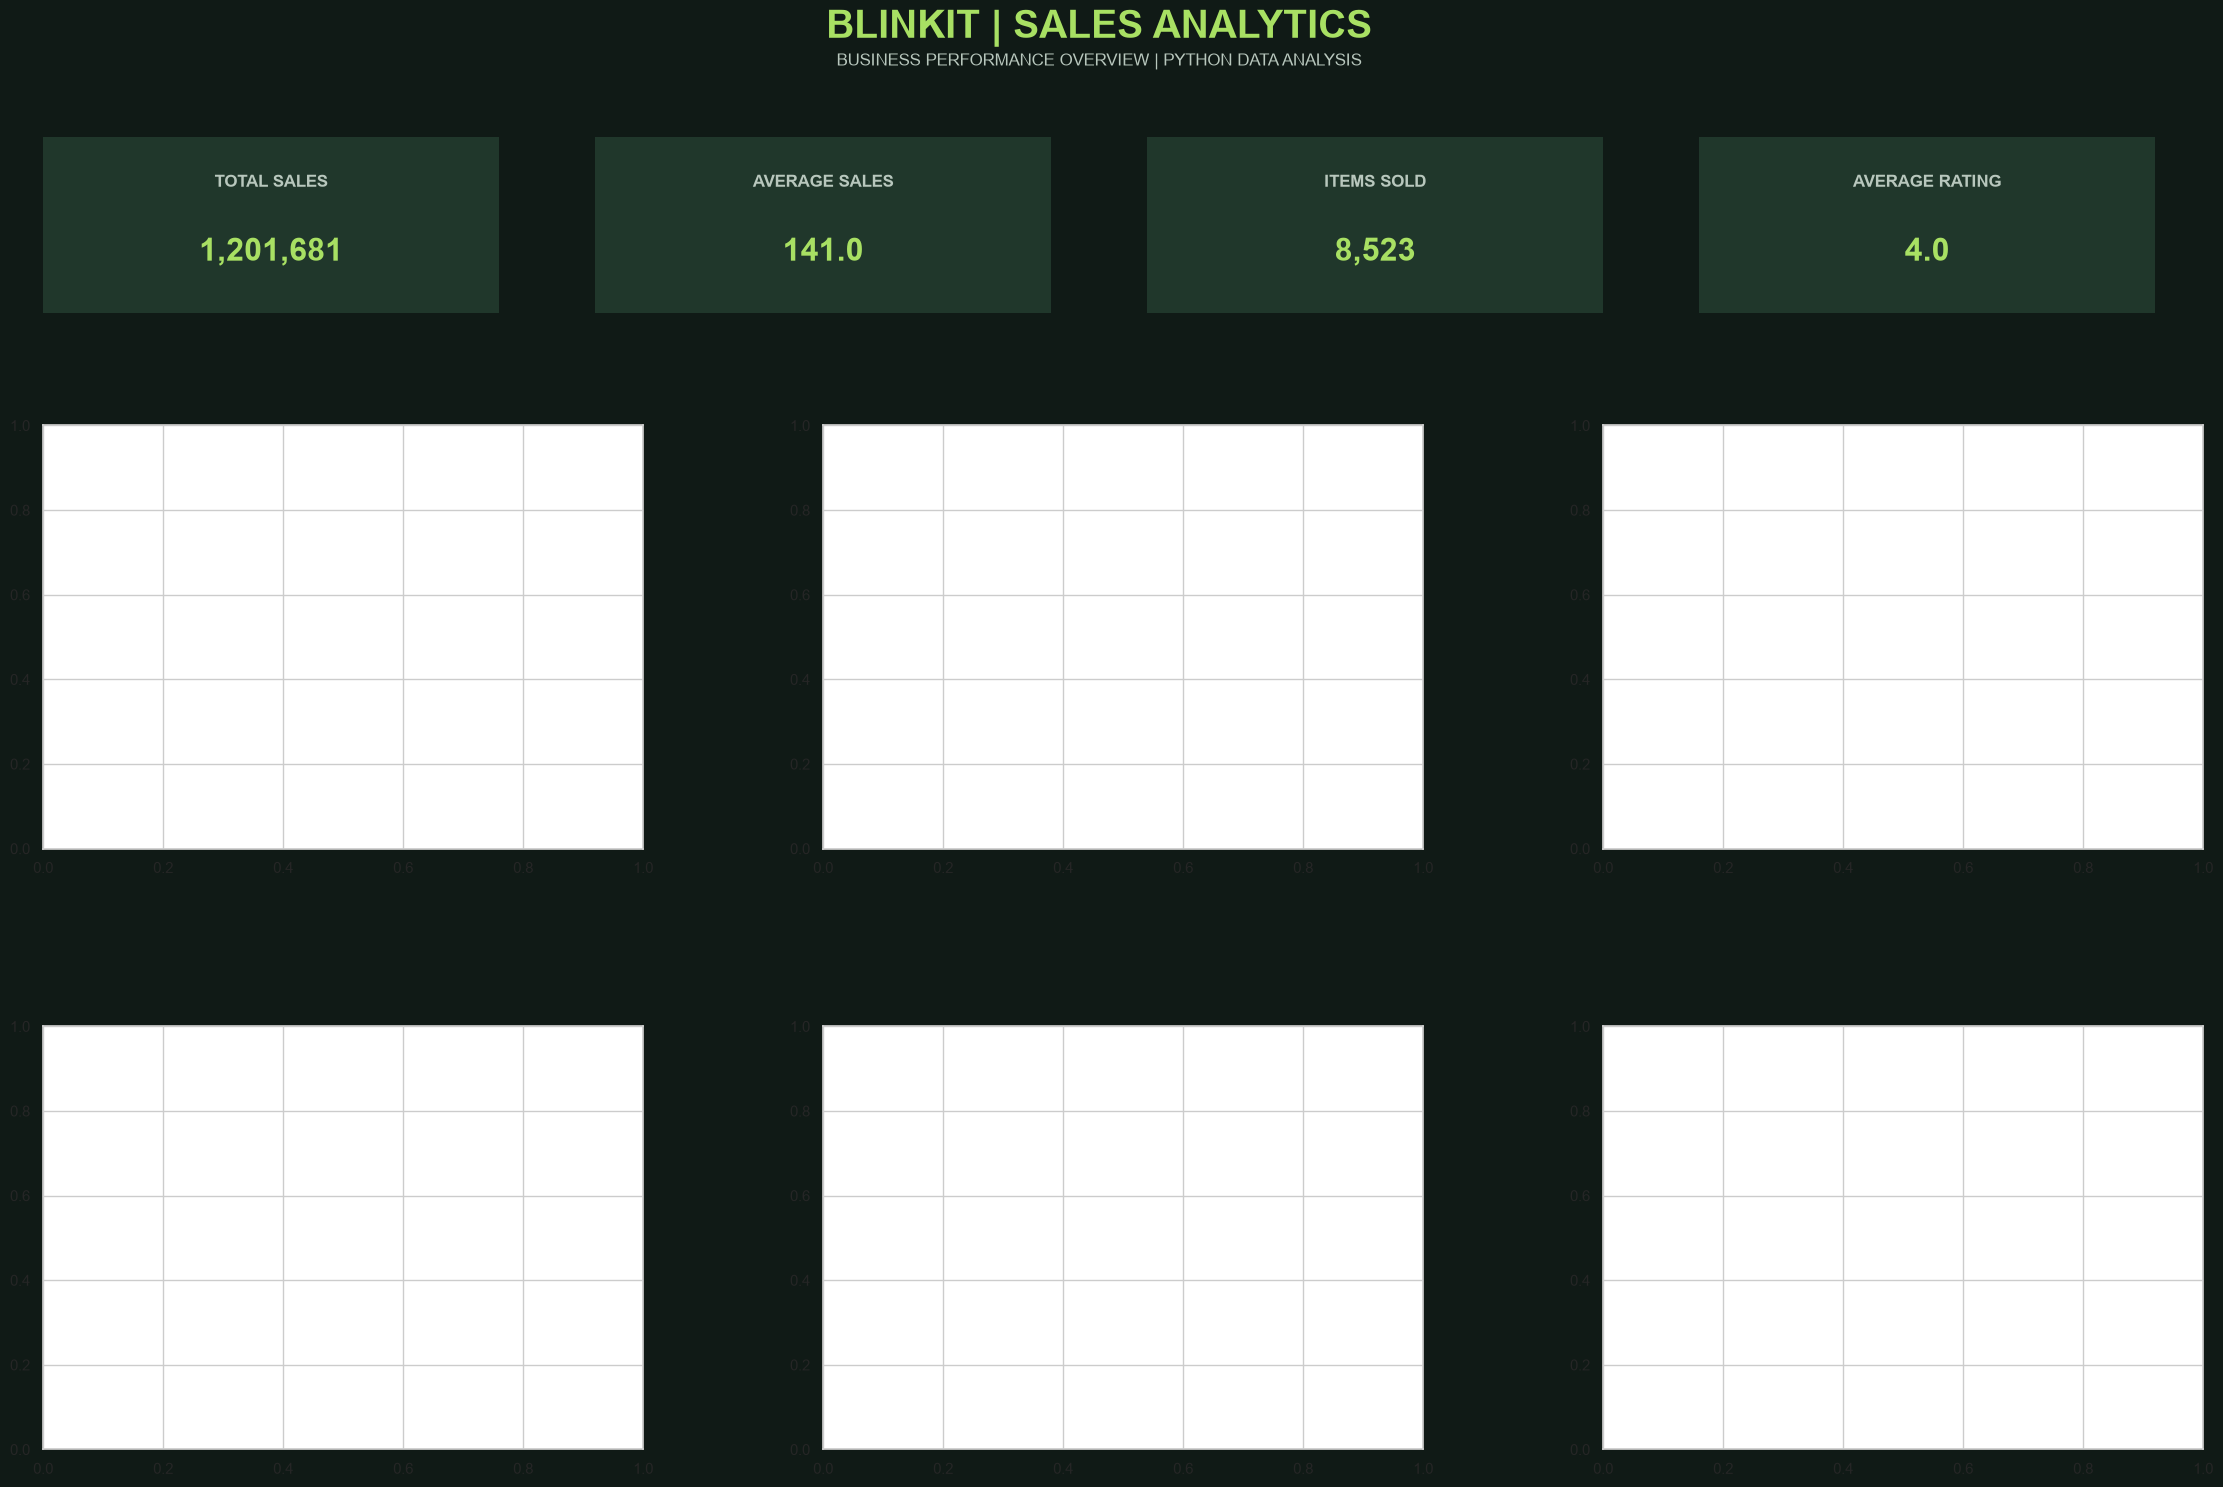

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

BG = "#101A16"
CARD = "#20372B"
PANEL = "#1B2B23"
GREEN = "#A8E063"
WHITE = "#F5F7F4"
MUTED = "#B8C7BD"
ORANGE = "#F4A261"

sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(24, 16), facecolor=BG)

fig.suptitle(
    "BLINKIT | SALES ANALYTICS",
    fontsize=28,
    fontweight="bold",
    color=GREEN,
    y=0.98
)

fig.text(
    0.5, 0.945,
    "BUSINESS PERFORMANCE OVERVIEW | PYTHON DATA ANALYSIS",
    ha="center", fontsize=12, color=MUTED
)

# KPI section
kpi_positions = [0.06, 0.29, 0.52, 0.75]

kpis = [
    ("TOTAL SALES", f"{total_sales:,.0f}"),
    ("AVERAGE SALES", f"{avg_sales:,.1f}"),
    ("ITEMS SOLD", f"{no_of_items_sold:,}"),
    ("AVERAGE RATING", f"{avg_ratings:.1f}")
]

for x, (title, value) in zip(kpi_positions, kpis):
    ax = fig.add_axes([x, 0.79, 0.19, 0.11])
    ax.set_facecolor(CARD)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.text(0.5, 0.72, title, ha="center",
            color=MUTED, fontsize=12, fontweight="bold")

    ax.text(0.5, 0.30, value, ha="center",
            color=GREEN, fontsize=23, fontweight="bold")

# Six chart positions
gs = fig.add_gridspec(
    2, 3,
    left=0.06, right=0.96,
    bottom=0.08, top=0.72,
    hspace=0.42, wspace=0.30
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 0])
ax5 = fig.add_subplot(gs[1, 1])
ax6 = fig.add_subplot(gs[1, 2])

def style_axis(ax, title):
    ax.set_facecolor(PANEL)
    ax.set_title(title, color=GREEN,
                 fontsize=13, fontweight="bold", pad=12)
    ax.tick_params(colors=WHITE, labelsize=9)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

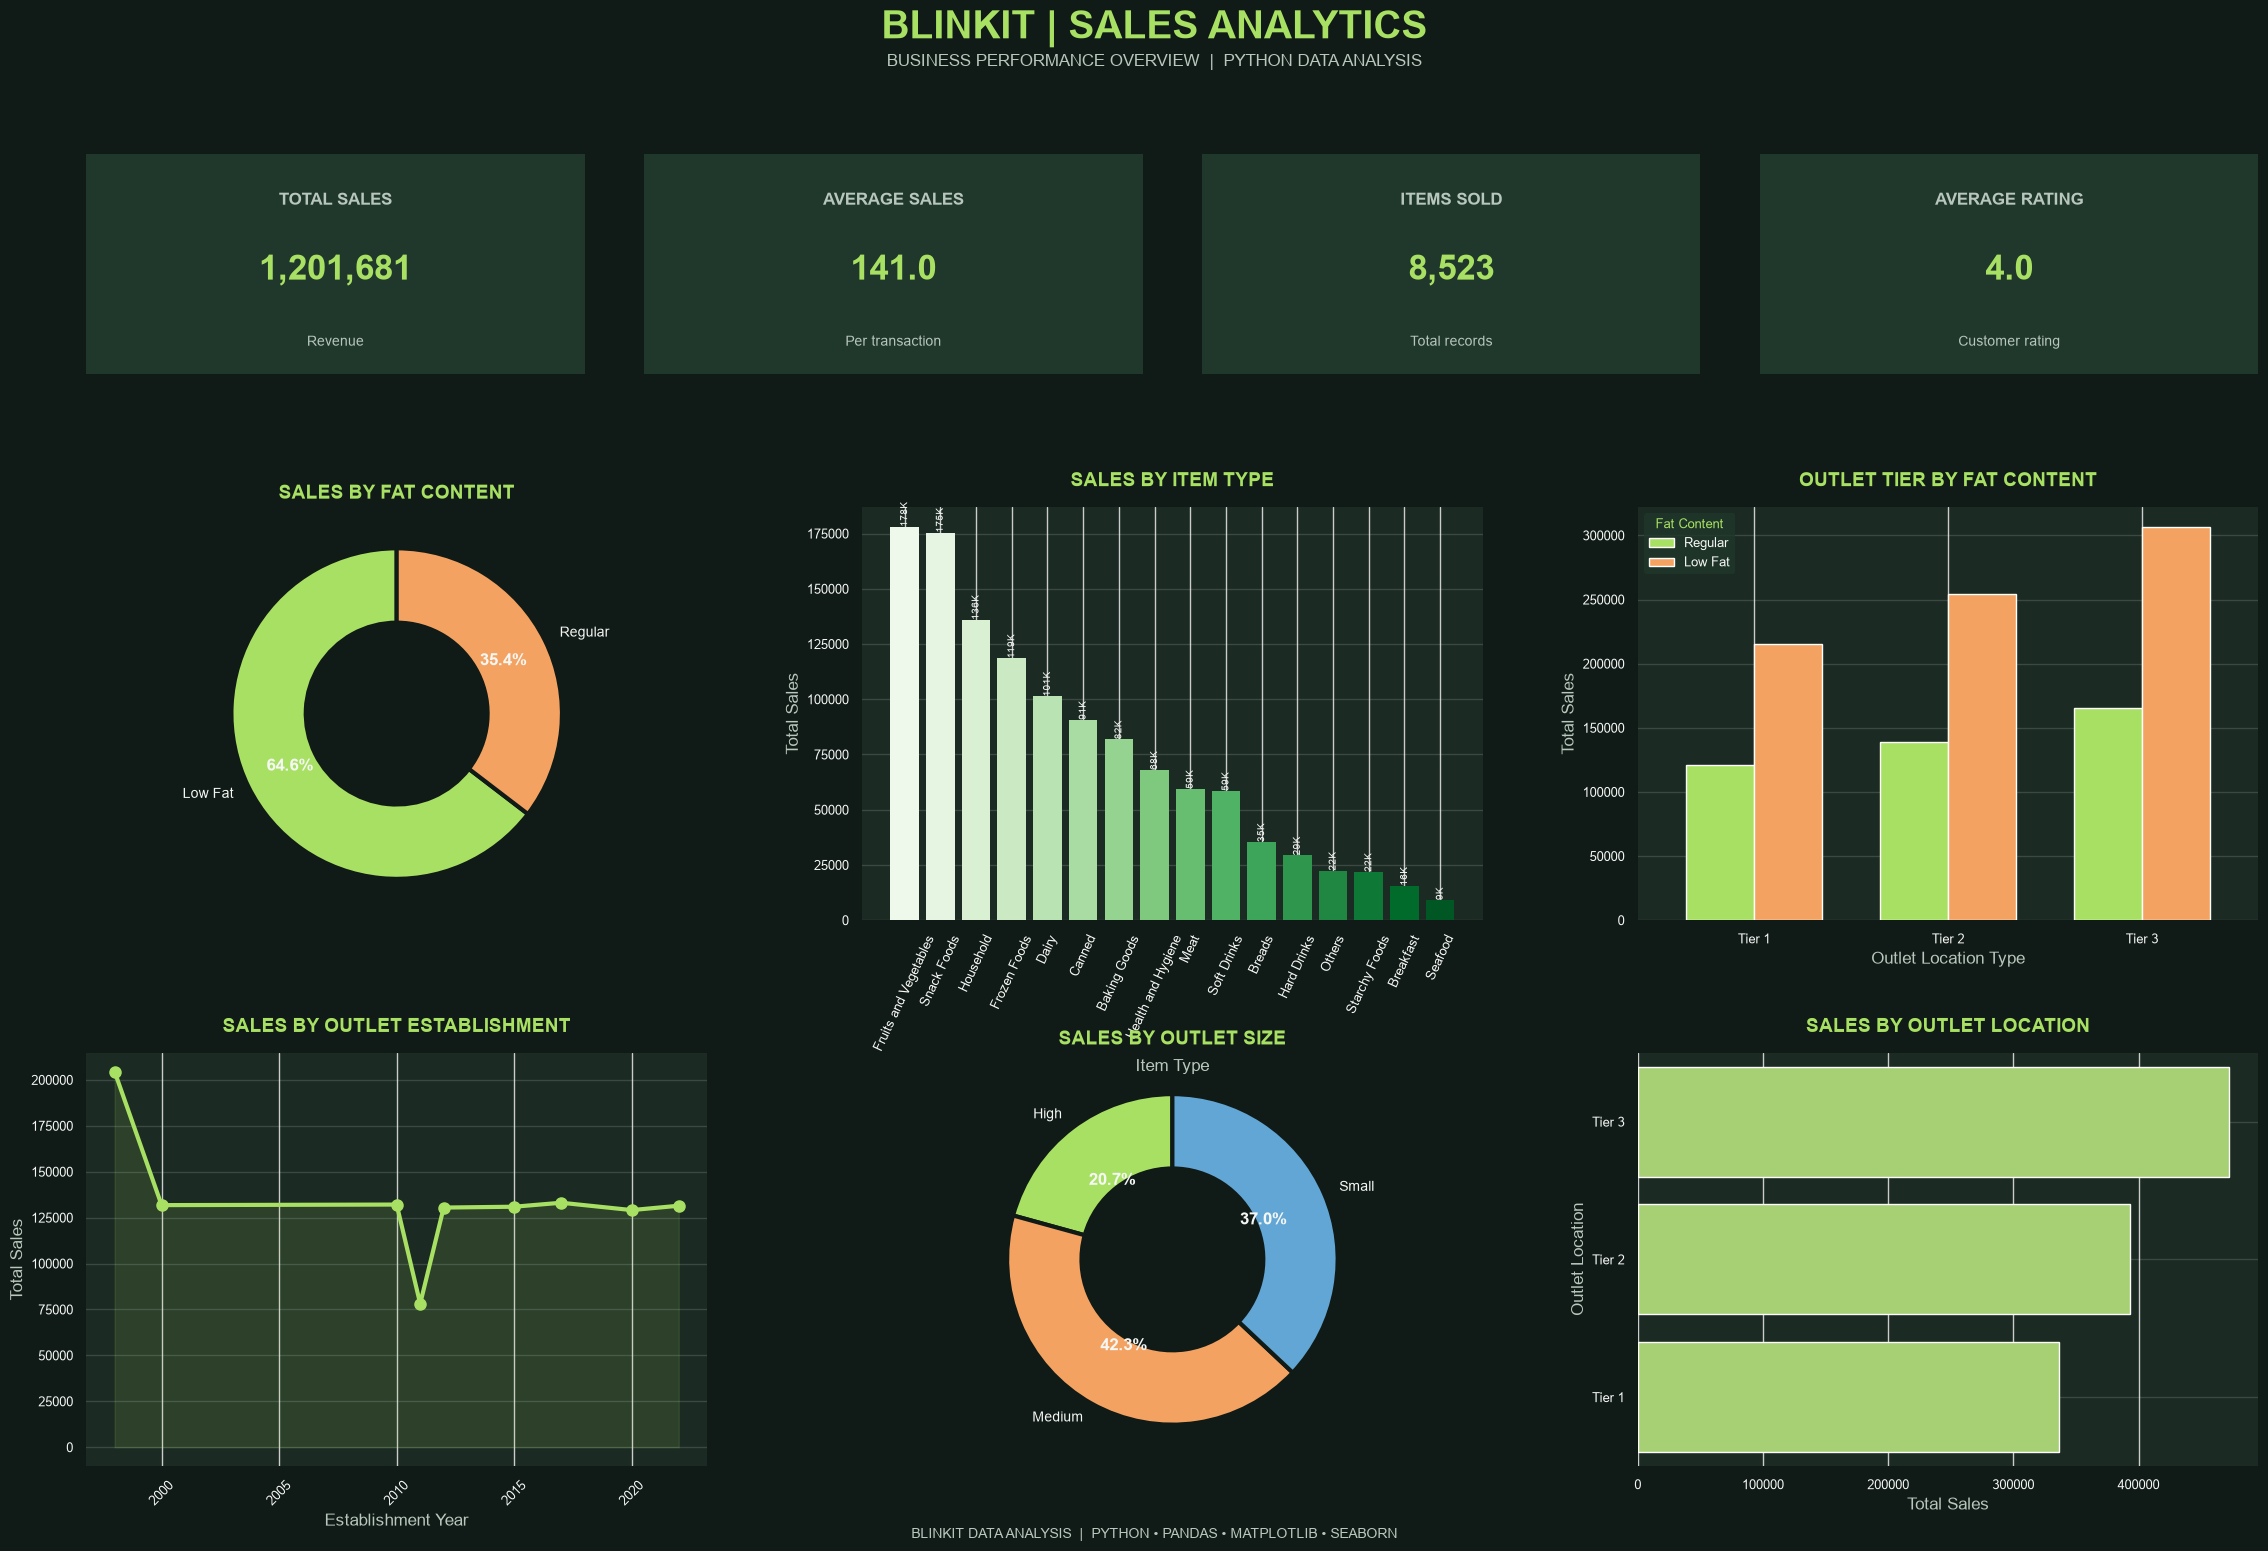

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

BG = "#101A16"
CARD = "#20372B"
PANEL = "#1B2B23"
GREEN = "#A8E063"
WHITE = "#F5F7F4"
MUTED = "#B8C7BD"
ORANGE = "#F4A261"

sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(24, 16), facecolor=BG)

fig.suptitle(
    "BLINKIT | SALES ANALYTICS",
    fontsize=28,
    fontweight="bold",
    color=GREEN,
    y=0.98
)

fig.text(
    0.5, 0.945,
    "BUSINESS PERFORMANCE OVERVIEW  |  PYTHON DATA ANALYSIS",
    ha="center",
    fontsize=12,
    color=MUTED
)

gs = fig.add_gridspec(
    3, 3,
    height_ratios=[0.8, 1.5, 1.5],
    left=0.055,
    right=0.96,
    top=0.89,
    bottom=0.07,
    hspace=0.38,
    wspace=0.25
)

# -----------------------------------------
# 1. KPI CARDS
# -----------------------------------------

kpi_grid = gs[0, :].subgridspec(1, 4, wspace=0.12)

kpis = [
    ("TOTAL SALES", f"{total_sales:,.0f}", "Revenue"),
    ("AVERAGE SALES", f"{avg_sales:,.1f}", "Per transaction"),
    ("ITEMS SOLD", f"{no_of_items_sold:,}", "Total records"),
    ("AVERAGE RATING", f"{avg_ratings:.1f}", "Customer rating")
]

for i, (title, value, subtitle) in enumerate(kpis):

    ax = fig.add_subplot(kpi_grid[0, i])
    ax.set_facecolor(CARD)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.text(
        0.5, 0.77, title,
        ha="center",
        color=MUTED,
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.43, value,
        ha="center",
        color=GREEN,
        fontsize=25,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.13, subtitle,
        ha="center",
        color=MUTED,
        fontsize=10
    )

# -----------------------------------------
# COMMON CHART STYLING
# -----------------------------------------

def style_axis(ax, title):

    ax.set_facecolor(PANEL)
    ax.set_title(
        title,
        color=GREEN,
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    ax.tick_params(colors=WHITE, labelsize=9)

    ax.xaxis.label.set_color(MUTED)
    ax.yaxis.label.set_color(MUTED)

    ax.grid(axis="y", alpha=0.15, color=WHITE)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

# -----------------------------------------
# 2. SALES BY FAT CONTENT
# -----------------------------------------

ax1 = fig.add_subplot(gs[1, 0])

wedges, texts, autotexts = ax1.pie(
    sales_by_fat,
    labels=sales_by_fat.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[GREEN, ORANGE],
    pctdistance=0.72,
    wedgeprops=dict(
        width=0.45,
        edgecolor=BG,
        linewidth=3
    )
)

for text in texts:
    text.set_color(WHITE)
    text.set_fontsize(10)

for text in autotexts:
    text.set_color(WHITE)
    text.set_fontweight("bold")

ax1.set_title(
    "SALES BY FAT CONTENT",
    color=GREEN,
    fontsize=14,
    fontweight="bold"
)
ax1.set_facecolor(PANEL)

# -----------------------------------------
# 3. TOTAL SALES BY ITEM TYPE
# -----------------------------------------

ax2 = fig.add_subplot(gs[1, 1])

colors = sns.color_palette(
    "Greens",
    n_colors=len(sales_by_type)
)

bars = ax2.bar(
    sales_by_type.index,
    sales_by_type.values,
    color=colors,
    edgecolor="none"
)

style_axis(ax2, "SALES BY ITEM TYPE")

ax2.set_xlabel("Item Type")
ax2.set_ylabel("Total Sales")
ax2.tick_params(axis="x", rotation=65)

for bar in bars:
    ax2.annotate(
        f"{bar.get_height()/1000:.0f}K",
        (bar.get_x() + bar.get_width()/2,
         bar.get_height()),
        ha="center",
        va="bottom",
        color=WHITE,
        fontsize=7,
        rotation=90
    )

# -----------------------------------------
# 4. OUTLET TIER BY FAT CONTENT
# -----------------------------------------

ax3 = fig.add_subplot(gs[1, 2])

grouped.plot(
    kind="bar",
    ax=ax3,
    color=[GREEN, ORANGE],
    width=0.7
)

style_axis(ax3, "OUTLET TIER BY FAT CONTENT")

ax3.set_xlabel("Outlet Location Type")
ax3.set_ylabel("Total Sales")
ax3.tick_params(axis="x", rotation=0)

legend = ax3.legend(
    title="Fat Content",
    fontsize=9,
    title_fontsize=9,
    facecolor=CARD,
    edgecolor="none"
)

plt.setp(legend.get_texts(), color=WHITE)
legend.get_title().set_color(GREEN)

# -----------------------------------------
# 5. OUTLET ESTABLISHMENT
# -----------------------------------------

ax4 = fig.add_subplot(gs[2, 0])

ax4.plot(
    sales_by_year.index,
    sales_by_year.values,
    marker="o",
    linewidth=3,
    markersize=8,
    color=GREEN
)

ax4.fill_between(
    sales_by_year.index,
    sales_by_year.values,
    color=GREEN,
    alpha=0.12
)

style_axis(ax4, "SALES BY OUTLET ESTABLISHMENT")

ax4.set_xlabel("Establishment Year")
ax4.set_ylabel("Total Sales")
ax4.tick_params(axis="x", rotation=45)

# -----------------------------------------
# 6. SALES BY OUTLET SIZE
# -----------------------------------------

ax5 = fig.add_subplot(gs[2, 1])

wedges, texts, autotexts = ax5.pie(
    sales_by_size,
    labels=sales_by_size.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[GREEN, ORANGE, "#62A6D5"],
    wedgeprops=dict(
        width=0.45,
        edgecolor=BG,
        linewidth=3
    )
)

for text in texts:
    text.set_color(WHITE)
    text.set_fontsize(10)

for text in autotexts:
    text.set_color(WHITE)
    text.set_fontweight("bold")

ax5.set_title(
    "SALES BY OUTLET SIZE",
    color=GREEN,
    fontsize=14,
    fontweight="bold"
)
ax5.set_facecolor(PANEL)

# -----------------------------------------
# 7. SALES BY OUTLET LOCATION
# -----------------------------------------

ax6 = fig.add_subplot(gs[2, 2])

sns.barplot(
    x="Sales",
    y="Outlet Location Type",
    data=sales_by_location,
    ax=ax6,
    color=GREEN
)

style_axis(ax6, "SALES BY OUTLET LOCATION")

ax6.set_xlabel("Total Sales")
ax6.set_ylabel("Outlet Location")

# -----------------------------------------
# FOOTER
# -----------------------------------------

fig.text(
    0.5, 0.025,
    "BLINKIT DATA ANALYSIS  |  PYTHON • PANDAS • MATPLOTLIB • SEABORN",
    ha="center",
    fontsize=10,
    color=MUTED
)

# Save high-quality dashboard
plt.savefig(
    "Blinkit_Premium_Dashboard.png",
    dpi=300,
    facecolor=BG,
    bbox_inches="tight"
)

plt.show()